## PCA applied to the handwritten digits dataset

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.decomposition import PCA


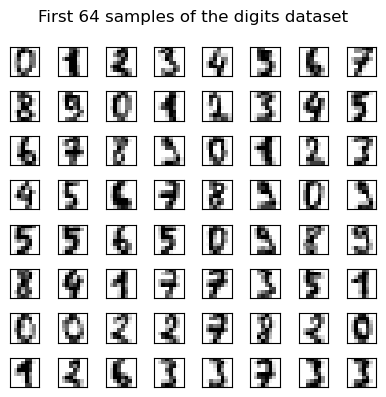

In [2]:
# Load the handwritten digits dataset
digits = datasets.load_digits()
X = digits.data
y = digits.target

# Plot the first 64 samples in a 8x8 grid
fig, ax = plt.subplots(8, 8, figsize=(4, 4))
for i, axi in enumerate(ax.flat):
    axi.imshow(digits.images[i], cmap='binary')
    axi.set(xticks=[], yticks=[])
fig.suptitle("First 64 samples of the digits dataset")
fig.tight_layout()
plt.show()


## Visualizing the first 2 principal components of the handwritten digits dataset

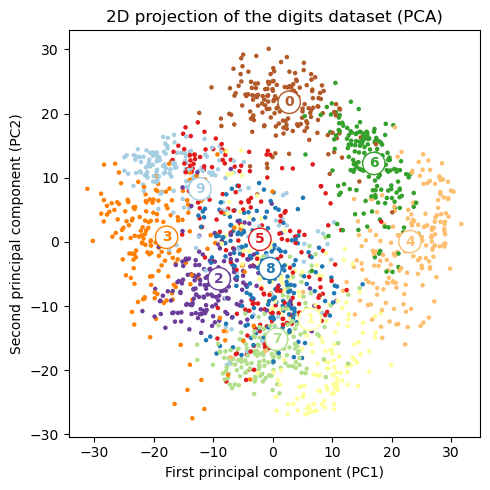

In [3]:
# Create a PCA model that keeps two features
pca = PCA(n_components=2)

# Fit and transform the data to the model
reduced_data_pca = pca.fit_transform(X)

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
handle = ax.scatter(reduced_data_pca[:, 0], reduced_data_pca[:, 1], c=digits.target, cmap='Paired_r', s=5)
ax.set_title("2D projection of the digits dataset (PCA)")
ax.set_xlabel("First principal component (PC1)")
ax.set_ylabel("Second principal component (PC2)")

# Add labels with the digit number at the center of each cluster
for i in np.unique(digits.target):
    xtext, ytext = reduced_data_pca[digits.target == i].mean(axis=0)
    color = handle.get_cmap()(i/(len(np.unique(digits.target))-1))
    ax.annotate(
        f"{i}", (xtext, ytext), fontsize=10, fontweight='bold', color=color,
        bbox=dict(facecolor='white', edgecolor=color, boxstyle='circle')
    )

fig.tight_layout()
plt.show()